In [3]:
import cv2
import matplotlib.pyplot as plt
import albumentations as A

In [4]:
#Функція завантаження зображення

def load_image(image_path):
    image = cv2.imread(image_path)
    if image is None:
        raise FileNotFoundError(
            "File not found. Please check the path and try again.")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    return image

In [5]:
#Функція візуалізації зображень через Matplotlib
def display_image(images, titles=None, figsize=(15, 5)):

    n = len(images)
    plt.figure(figsize=figsize)
    for i in range(n):
        plt.subplot(1, n, i + 1)
        plt.imshow(images[i])
        if titles and i < len(titles):
            plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

In [6]:
#Функція для застосування аугментацій
def augment_image(image, transform_pipeline, num_samples=3):
    augmented_images = []
    for _ in range(num_samples):
        augmented = transform_pipeline(image=image)
        augmented_images.append(augmented['image'])
    return augmented_images


In [7]:
#Блок аугментацій
image_paths = ['Dwayne.jpg', 'gordon.jpeg', 'JasonStatham.jpeg', 'Vin_Diesel.jpeg']

transform = A.Compose([
    A.RandomCrop(width=300, height=300, p=1.0),
    A.RandomBrightnessContrast(p=0.8),
    A.GaussNoise(p=0.8),
    A.Rotate(limit=25, p=0.5)
])


Processing [1/4]: Dwayne.jpg


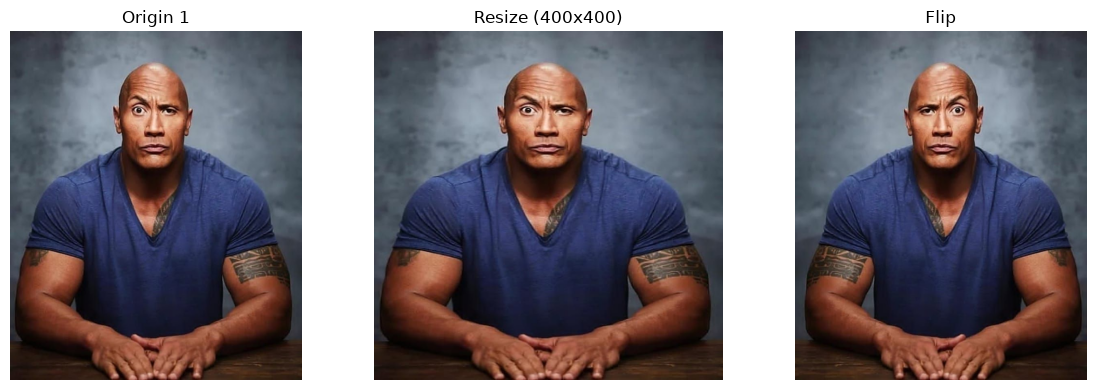

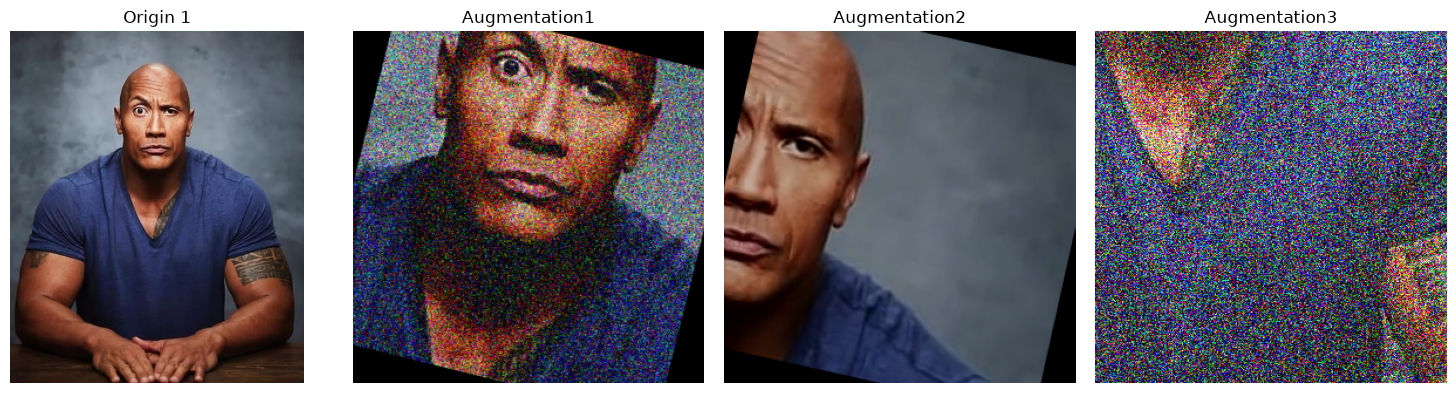


Processing [2/4]: gordon.jpeg


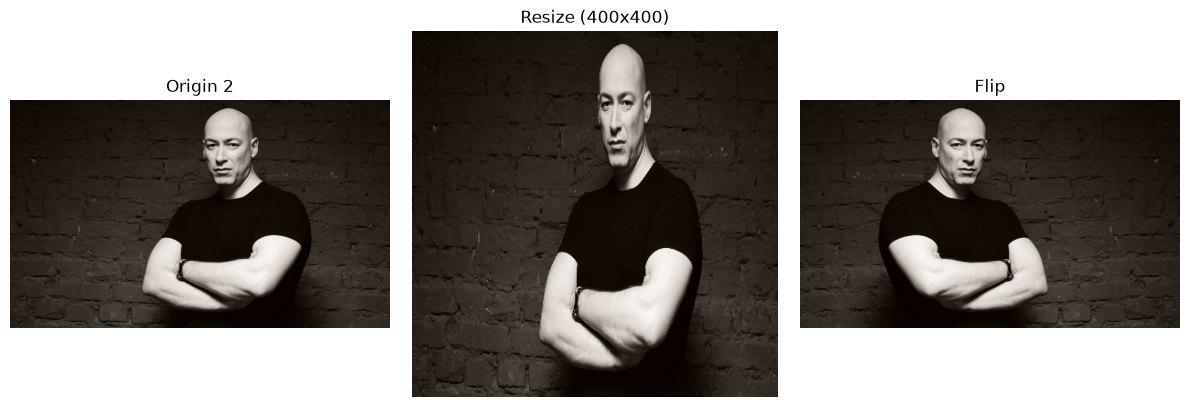

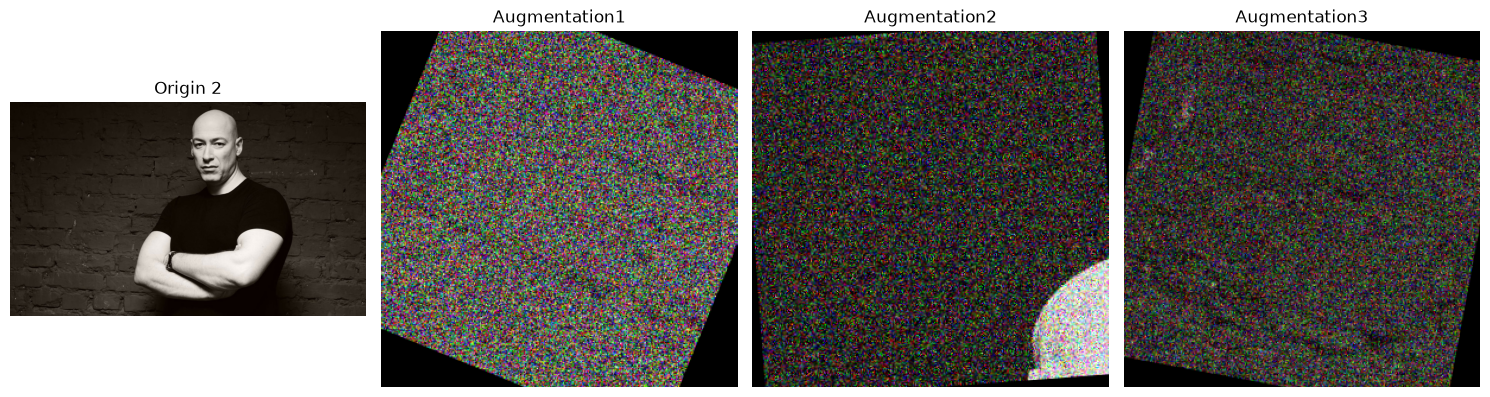


Processing [3/4]: JasonStatham.jpeg


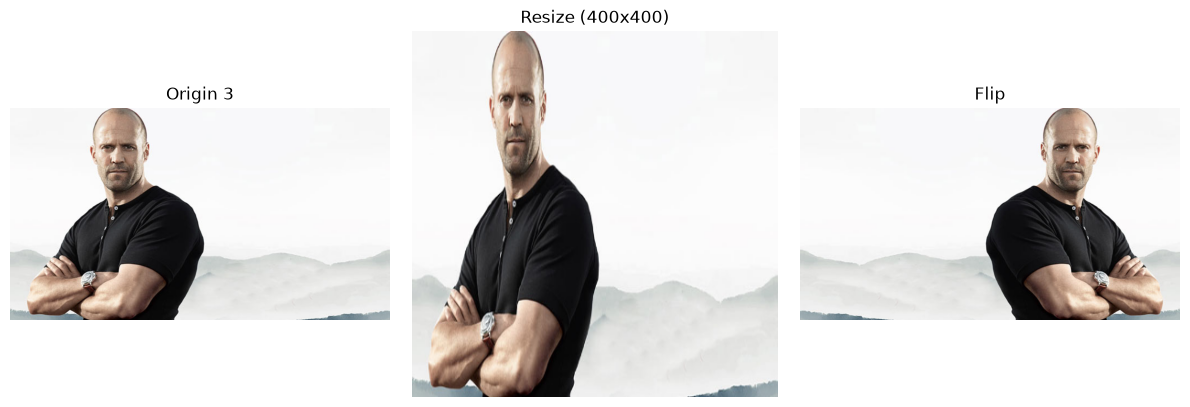

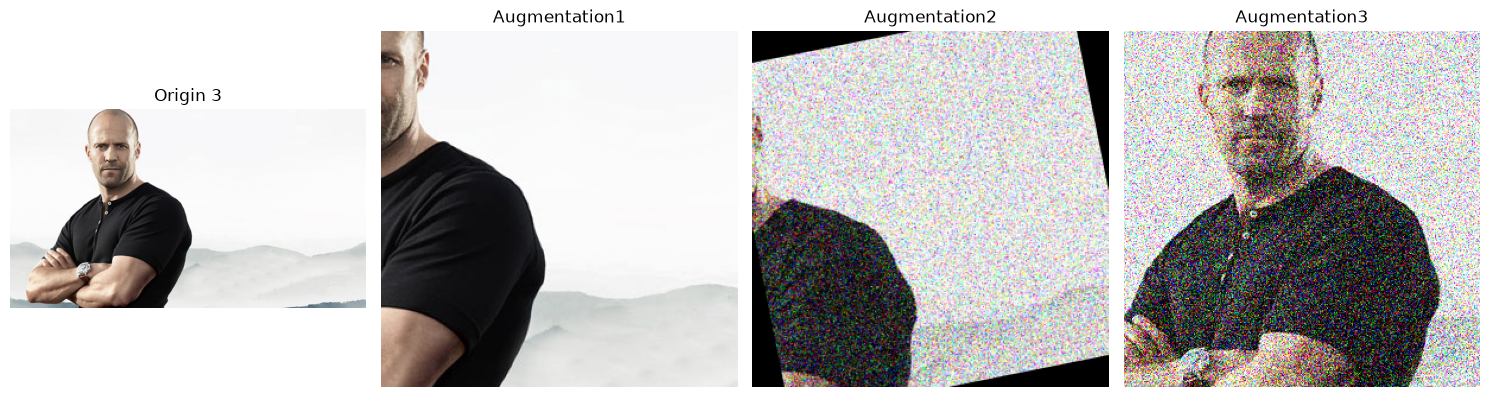


Processing [4/4]: Vin_Diesel.jpeg


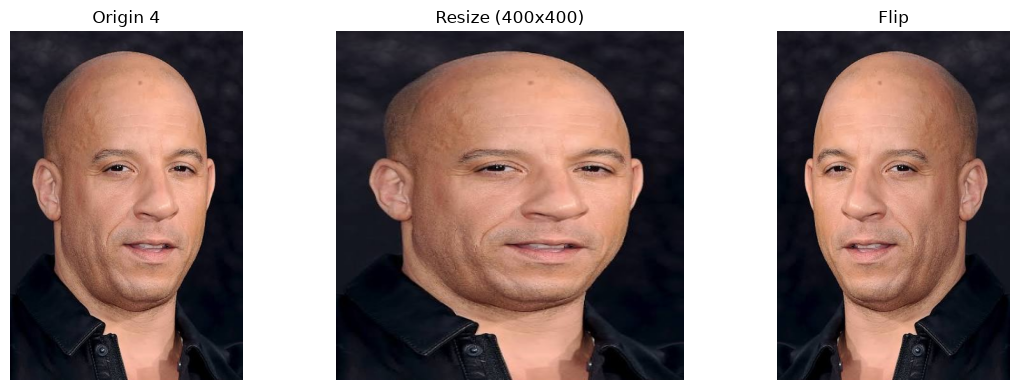

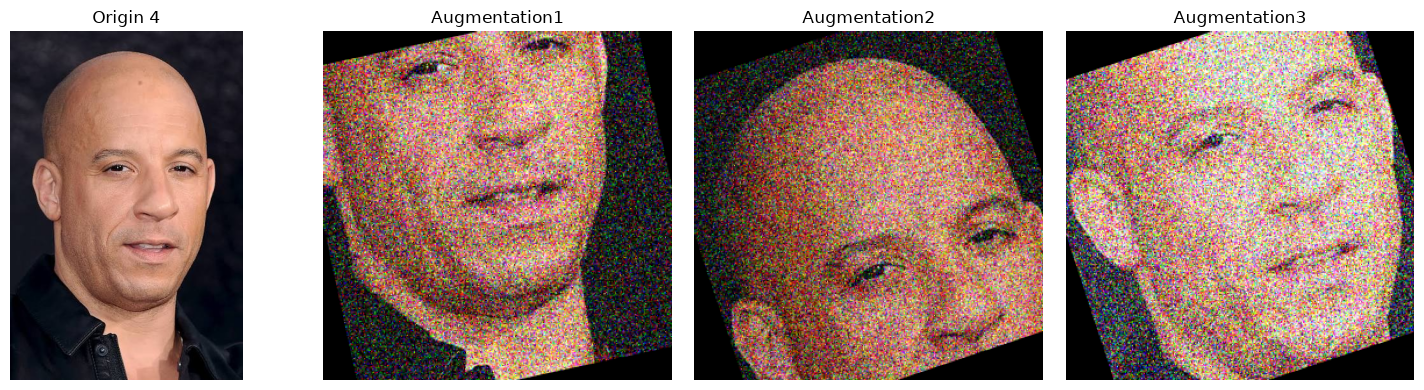

In [9]:
#Цикл що проходить по кожному зображенню та кіцеві результати аугментацій.
for i, path in enumerate(image_paths):
    print(f"\nProcessing [{i + 1}/4]: {path}")

    try:
        original_image = load_image(path)
        h, w = original_image.shape[:2]
        resized_img = cv2.resize(original_image, (400, 400))
        flipped_img = cv2.flip(original_image, 1)
        display_image(
            [original_image, resized_img, flipped_img],
            titles=[f'Origin {i + 1}', 'Resize (400x400)', 'Flip'],
            figsize=(12, 4)
        )

        augmented_results = augment_image(original_image, transform, num_samples=3)

        display_image(
            [original_image] + augmented_results,
            titles=[f'Origin {i + 1}', 'Augmentation1', 'Augmentation2', 'Augmentation3'],
            figsize=(15, 4)
        )

    except FileNotFoundError as e:
        print(f"⚠️ missing: {e}")